In [ ]:
import pandas as pd
import schema_loader as loader
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

sns.set_theme(style="whitegrid")


DATA_PATH = "data/training/sample_flights.parquet"
COLS = ["route", "departure_date", "observed_date", "price", "airline", "stops", "duration"]
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SAMPLE_N = 50_000
SEED = 42

In [ ]:
# load only the necessary columns
df = loader.load_flights(DATA_PATH)
info = loader.validate(df)

print(info)
print(df.shape)
df.info(memory_usage="deep")

# sample the data
sample = df.sample(SAMPLE_N, random_state=SEED)

route_sample = (df.groupby("route", group_keys=False)
                .sample(n=5_000, random_state=SEED, replace=False)
                if df["route"].value_counts().min() >= 5_000
                else df.groupby("route", observed=True, group_keys=False)
                .sample(frac=0.02, random_state=SEED))

In [71]:
# %% [Markdown]
# ## 1. Sanity and shape

In [ ]:
#  %%
print("Rows per route: ")
print(df["route"].value_counts(), "\n")

print("Rows per airline (top 10): ")
print(df["airline"].value_counts().head(10), "\n")

print("Observed search date range:",
      df["observed_date"].min(), "to",
      df["observed_date"].max())

print("Departure date range:",
      df["departure_date"].min(),
      df["departure_date"].max())

print("\nNulls: ")
print(df.isna().sum())

print("\ndays_before_departure summary:")
print(df["days_before_departure"].describe())
print("Negative days_before_departure:",
      (df["days_before_departure"] < 0).sum())

Rows per route: 
route
LAS-LAX    826013
SEA-LAX    820025
LAX-ATL    732983
EWR-SFO    680098
BOS-LAX    673173
MSP-ORD    668088
LAX-IAH    515012
Name: count, dtype: Int64 

Rows per airline (top 10): 
airline
United Airlines                        1404072
Delta Air Lines                        1190287
American Airlines                       744653
Southwest Airlines                      503277
Alaska Airlines                         404747
Frontier Airlines                       345422
JetBlue Airways                         193029
JSX                                      41159
American Airlines + Alaska Airlines      32902
Spirit Airlines                          32343
Name: count, dtype: int64 

Dropped: airline
Sun Country Airlines                   10901
Alaska Airlines + American Airlines     4919
Alaska Airlines + Hawaiian Airlines     4358
Contour Airlines                        2572
Key Lime Air                             751
Name: count, dtype: int64
Observed search date 

In [ ]:
# %% [Markdown]
# ## 2. Price distribution

count    4.915392e+06
mean     2.282438e+02
std      1.388535e+02
min      1.900000e+01
1%       5.400000e+01
5%       7.600000e+01
50%      1.930000e+02
95%      4.990000e+02
99%      7.120000e+02
max      4.196000e+03
Name: price, dtype: float64


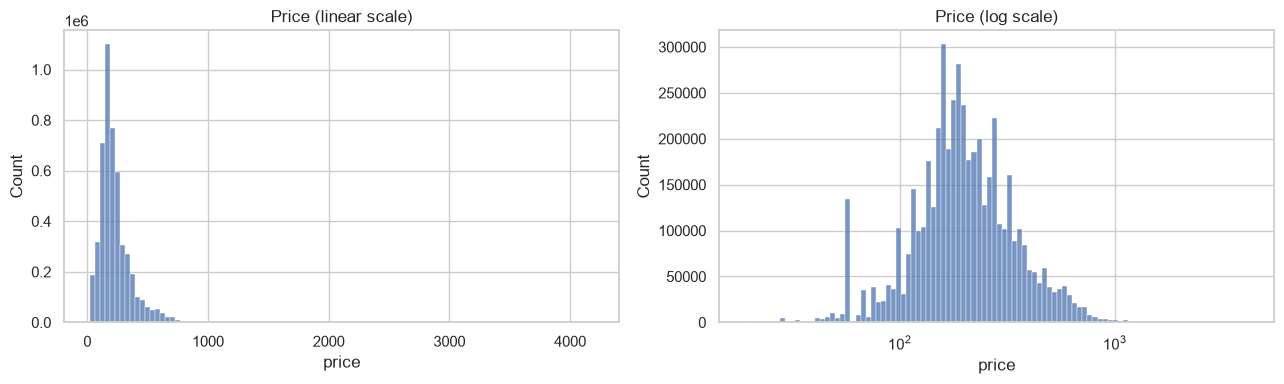

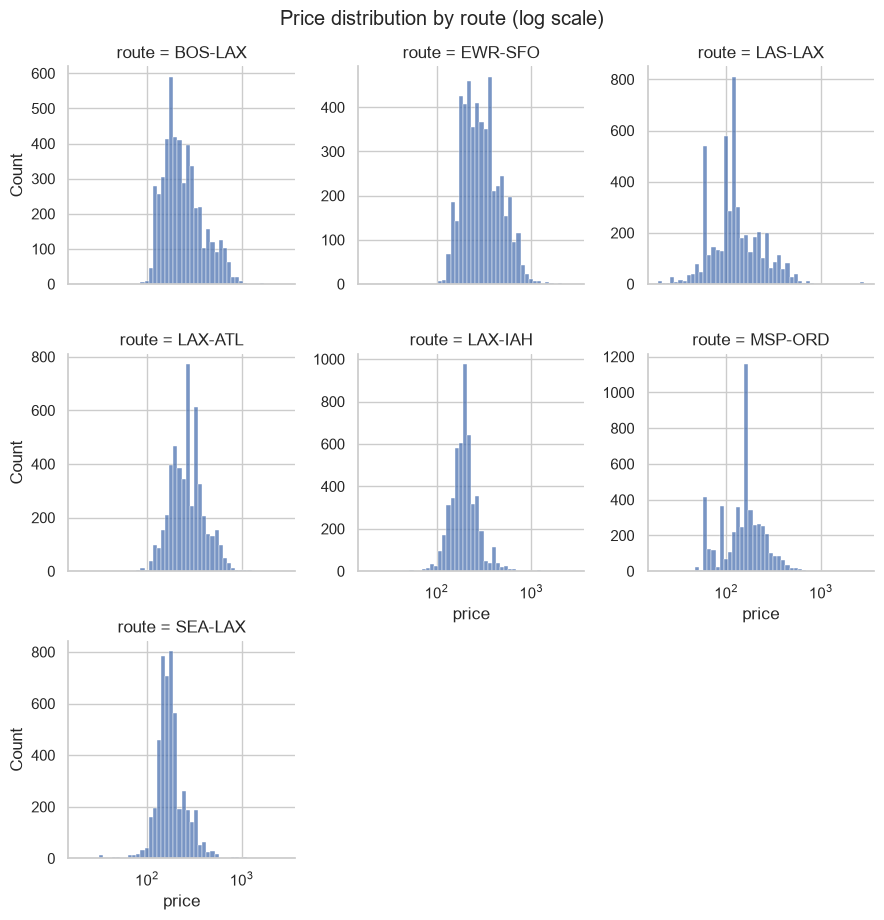

Skew (raw): 2.8702772969319206
Skew (log): -0.06661405913461975


In [72]:
# %%

print(df["price"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price"], bins=100, ax=axes[0])
axes[0].set_title("Price (linear scale)")

sns.histplot(df["price"], bins=100, log_scale=True, ax=axes[1])
axes[1].set_title("Price (log scale)")

plt.tight_layout()
plt.show()

# price distribution per route
g = sns.displot(
    data=route_sample, x="price", col="route", col_wrap=3,
    bins=50, log_scale=True, height=3, facet_kws={"sharey": False},
    
)

g.figure.suptitle("Price distribution by route (log scale)", y=1.02)

plt.show()

# skew check
print("Skew (raw):", df["price"].skew())
print("Skew (log):", np.log1p(df["price"]).skew())


In [ ]:
# %% [Markdown]
# ## 3. Price vs. days-before-departure

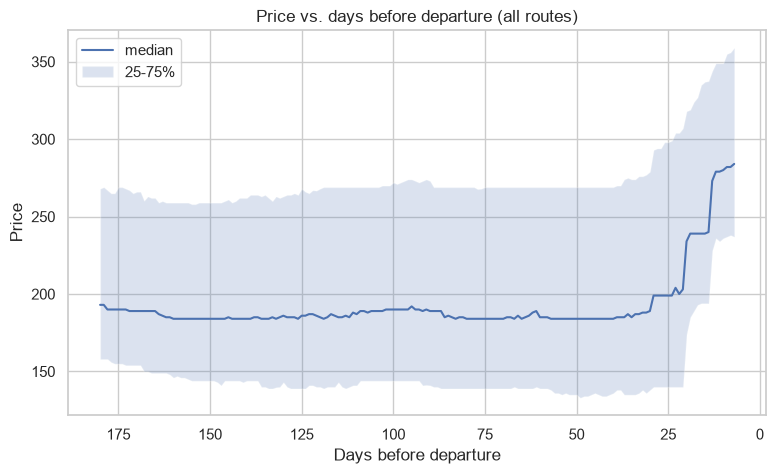

In [81]:
# %%
# Aggregate on full data and plot the summary

def dbd_summary(d):
    g = d.groupby("days_before_departure")["price"]

    return pd.DataFrame({
        "median": g.median(),
        "q25": g.quantile(0.25),
        "q75": g.quantile(0.75),
        "n": g.size(),
    }).reset_index()

overall = dbd_summary(df)

# drop days_before_departure with small frequencies
overall = overall[overall["n"] >= 100]

# plot summary
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(overall["days_before_departure"], overall["median"], label="median")
ax.fill_between(overall["days_before_departure"],
                overall["q25"], overall["q75"],
                alpha=0.2, label="25-75%")
ax.invert_xaxis() # decreasing days_before_departure

ax.set_xlabel("Days before departure")
ax.set_ylabel("Price")
ax.set_title("Price vs. days before departure (all routes)")
ax.legend()
plt.show()

Empty DataFrame
Columns: [route, days_before_departure, median, n]
Index: []


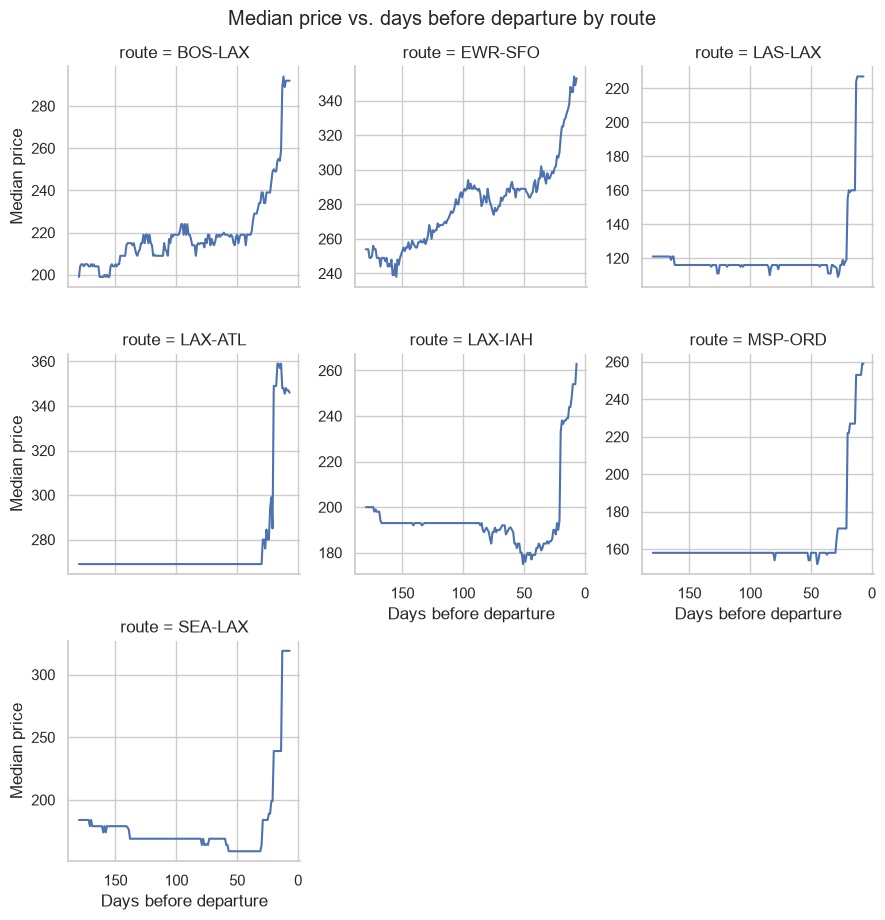

In [ ]:
# %%
# Facet data by route, median aggregated per route

per_route = (
    df.groupby(["route", "days_before_departure"])["price"]
    .agg(median="median", n="size")
    .reset_index()
)

per_route = per_route[per_route["n"] >= 30] # drop low frequency routes



g = sns.relplot(data=per_route, x="days_before_departure", y="median",
                col="route", col_wrap=3, kind="line", height=3,
                facet_kws={"sharey": False})


for ax in g.axes.flat:
    ax.invert_xaxis()

g.set_axis_labels("Days before departure", "Median price")
g.figure.suptitle("Median price vs. days before departure by route", y=1.02)
plt.show()

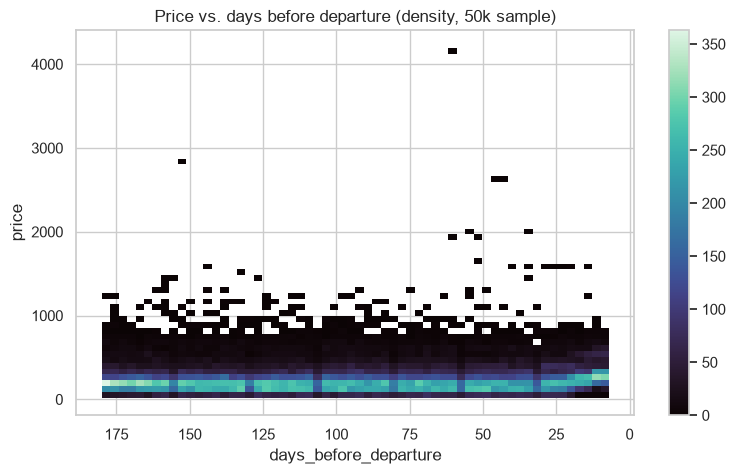

In [ ]:
# %%
# Density view on the sample, shows price spread that the median line doesn't show
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=sample, x="days_before_departure", y="price",
             bins=60, cmap="mako", cbar=True, ax=ax)
ax.invert_xaxis()
ax.set_title("Price vs. days before departure (density, 50k sample)")
plt.show()

In [ ]:
# %% [markdown]

In [ ]:
# %% [Markdown]

# ## Notes to self
# - Skew and outliers:
#   raw skew: 2.87028 
#   log skew: -0.06661 (may be better to model log price)
# - Shape of price vs. days-before-departure:
#   steep drop for the first month or so, then relatively stable price with very subtle fluctuation
# - Routes/Airlines with too few rows:
#   Sun Country Airlines                   10901
#   Alaska Airlines + American Airlines     4919
#   Alaska Airlines + Hawaiian Airlines     4358
#   Contour Airlines                        2572
#   Key Lime Air                             751